# Bài 4


# *PHẦN 1. CHUẨN BỊ MÔI TRƯỜNG

# Bước 1. Chuẩn bị môi trường và thư viện

In [24]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)

# Bước 2. Nạp dữ liệu

In [25]:
import pandas as pd

df = pd.read_csv('kc_house_data.csv')

print("Nạp dữ liệu thành công! Kích thước dữ liệu (Dòng, Cột):", df.shape)

display(df.head(5))

Nạp dữ liệu thành công! Kích thước dữ liệu (Dòng, Cột): (21613, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


# *PHẦN 2. EDA – EXPLORATORY DATA ANALYSIS

# Bước 3: Kiểm tra cấu trúc, kiểu dữ liệu và giá trị thiếu

In [26]:
print("Shape:", df.shape)

print("\nKiểu dữ liệu:")
print(df.dtypes)

print("\nSố giá trị thiếu:")
print(df.isnull().sum())

print("\nSố dòng trùng lặp:", df.duplicated().sum())

Shape: (21613, 21)

Kiểu dữ liệu:
id                 int64
date                 str
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object

Số giá trị thiếu:
id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: in

# Bước 4: Thống kê mô tả dữ liệu và trực quan hóa phân phối biến mục tiêu (price).

--- THỐNG KÊ MÔ TẢ DỮ LIỆU ---


,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


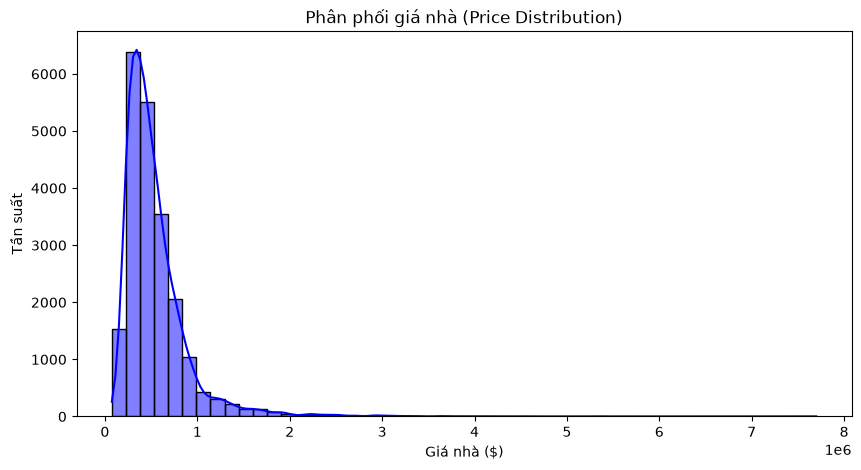

In [27]:
print("--- THỐNG KÊ MÔ TẢ DỮ LIỆU ---")
display(df.describe())

# Trực quan hóa phân phối của biến mục tiêu (price)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.histplot(df['price'], kde=True, color='blue', bins=50)
plt.title("Phân phối giá nhà (Price Distribution)")
plt.xlabel("Giá nhà ($)")
plt.ylabel("Tần suất")
plt.show()

 Nhận xét về Biểu đồ Phân phối giá nhà (Price Distribution):
* Hình dạng phân phối: Biểu đồ histogram và đường KDE cho thấy phân phối giá nhà lệch phải rõ rệt (Right-skewed).

* Mật độ tập trung: Phần lớn các căn nhà nằm ở phân khúc giá thấp và trung bình (từ dưới $500,000 đến $1,000,000).

* Giá trị ngoại lệ (Outliers): Đuôi biểu đồ kéo dài sang phải đến gần 8 triệu USD, thể hiện sự xuất hiện của một số ít các căn biệt thự/nhà siêu sang có giá trị cực cao.

# Bước 5. Phân tích phân phối từng biến 

In [28]:
feature_cols = X.columns.tolist()

for col in feature_cols + ["price"]:
    plt.figure(figsize=(6, 4))
    plt.hist(df[col], bins=25, edgecolor="black", alpha=0.8)
    plt.title(f"Phân phối của {col}")
    plt.xlabel(col)
    plt.ylabel("Tần suất")
    plt.grid(alpha=0.2)
    plt.show()

NameError: name 'X' is not defined

# Bước 6. Phát hiện ngoại lệ bằng IQR

In [ ]:
feature_cols = [col for col in df.columns if col not in ['id', 'date', 'price']]

outlier_summary = []

for col in feature_cols + ["price"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary.append([col, n_outliers, lower, upper])

outlier_df = pd.DataFrame(
    outlier_summary,
    columns=["Biến", "Số ngoại lệ theo IQR", "Ngưỡng dưới", "Ngưỡng trên"]
)

outlier_df

,Biến,Số ngoại lệ theo IQR,Ngưỡng dưới,Ngưỡng trên
0,bedrooms,546,1.5000,5.500000e+00
1,bathrooms,571,0.6250,3.625000e+00
2,sqft_living,572,-257.5000,4.234500e+03
3,sqft_lot,2425,-3432.0000,1.916000e+04
4,floors,0,-0.5000,3.500000e+00
5,waterfront,163,0.0000,0.000000e+00
6,view,2124,0.0000,0.000000e+00
7,condition,30,1.5000,5.500000e+00
8,grade,1911,5.5000,9.500000e+00
9,sqft_above,611,-340.0000,3.740000e+03


# Bước 7: Phân tích tương quan

In [ ]:
corr = df.corr(numeric_only=True)

target_corr = corr["price"].drop("price").sort_values(key=np.abs, ascending=False)

print("Tương quan với price:")
display(target_corr.to_frame("corr_with_price"))

Tương quan với price:


,corr_with_price
sqft_living,0.702035
grade,0.667434
sqft_above,0.605567
sqft_living15,0.585379
bathrooms,0.525138
view,0.397293
sqft_basement,0.323816
bedrooms,0.308350
lat,0.307003
waterfront,0.266369


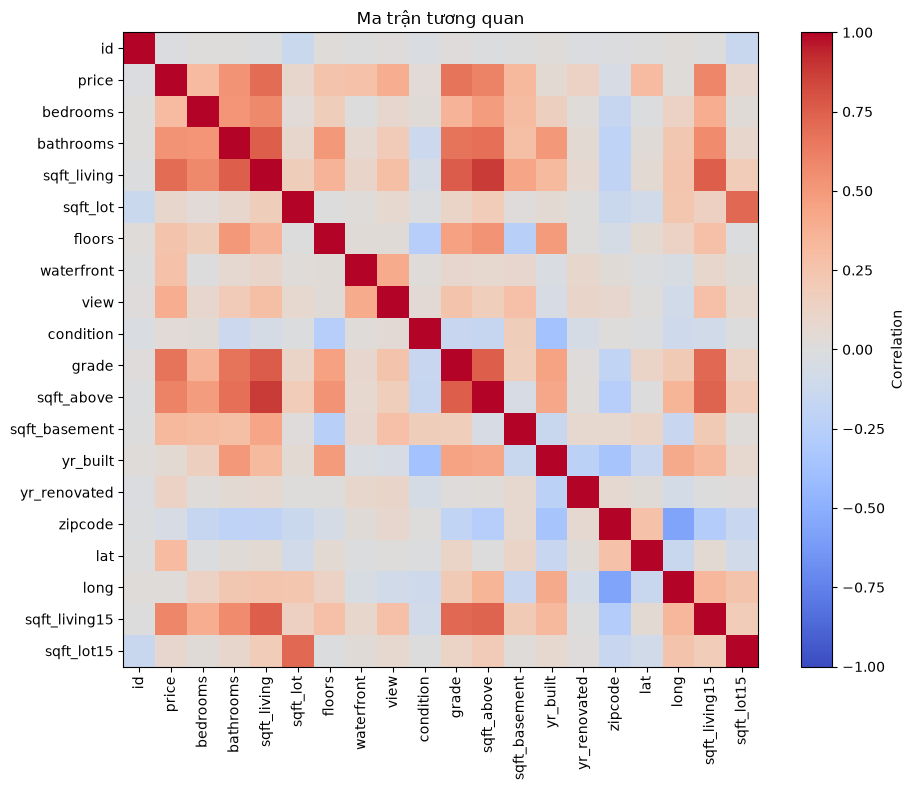

In [ ]:
#vẽ ma trận tương quan
plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)

plt.title("Ma trận tương quan")
plt.tight_layout()
plt.show()

# Bước 8. Quan hệ giữa từng feature và target

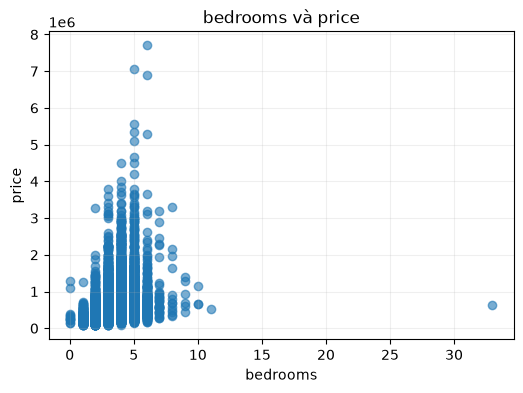

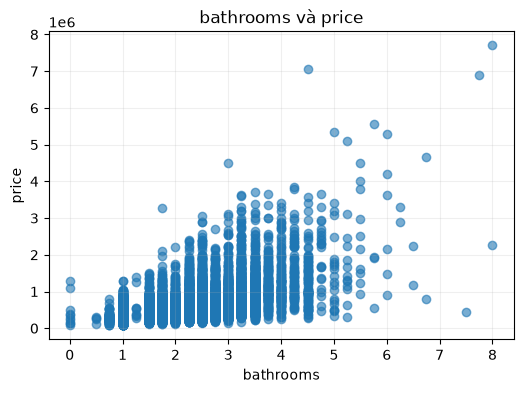

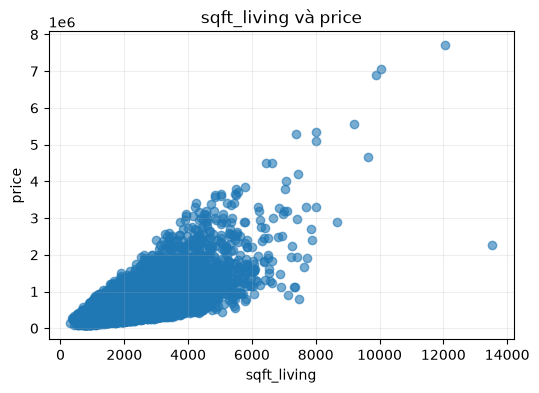

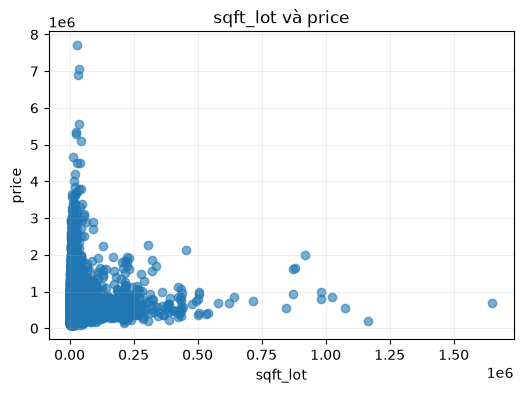

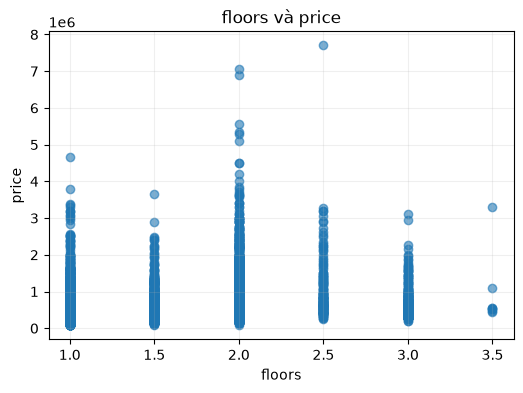

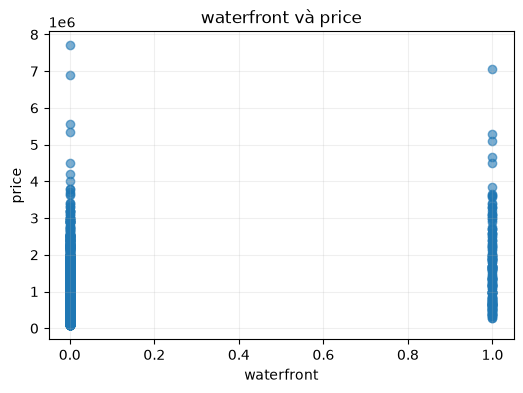

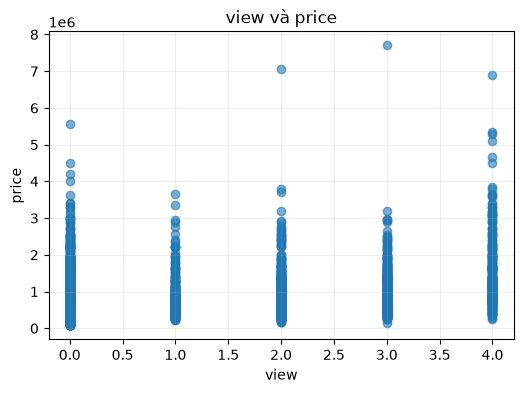

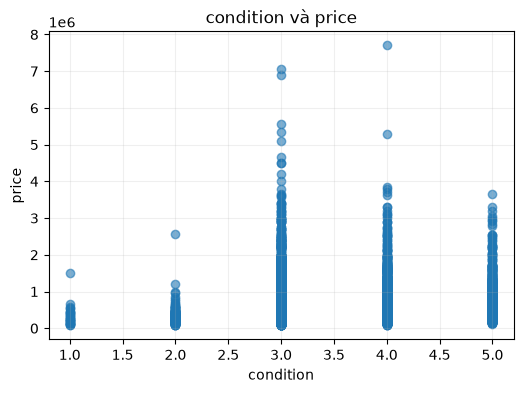

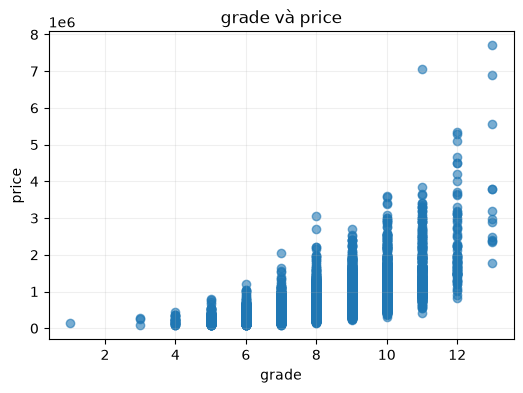

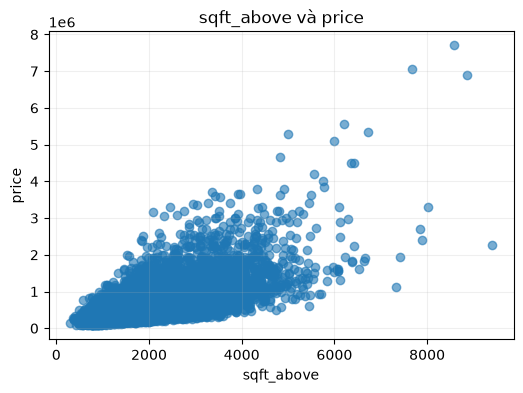

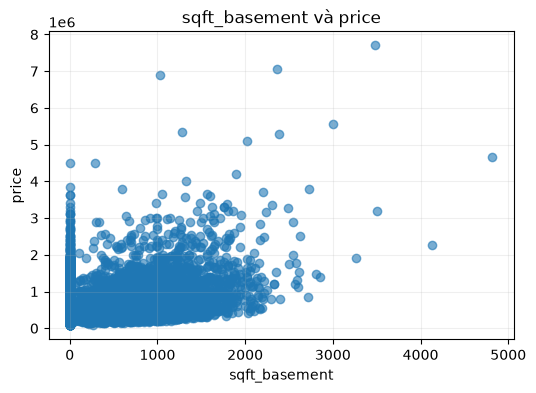

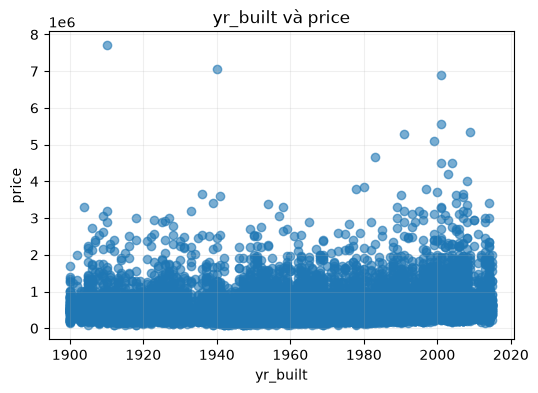

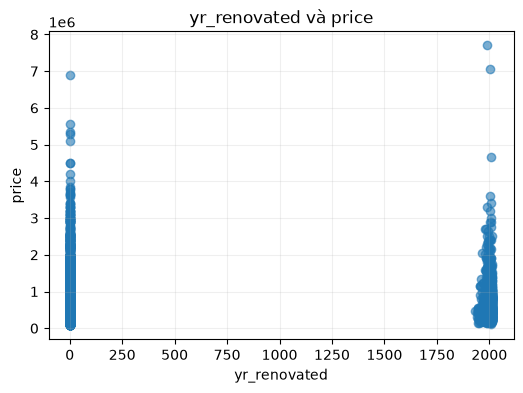

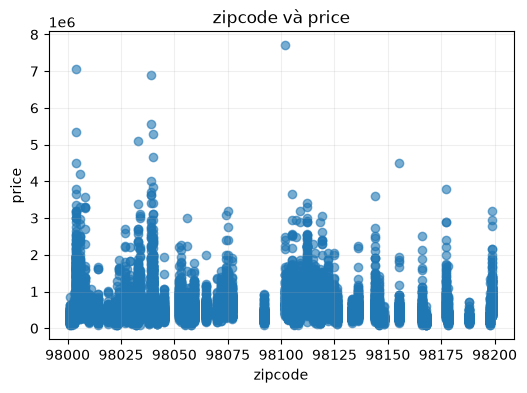

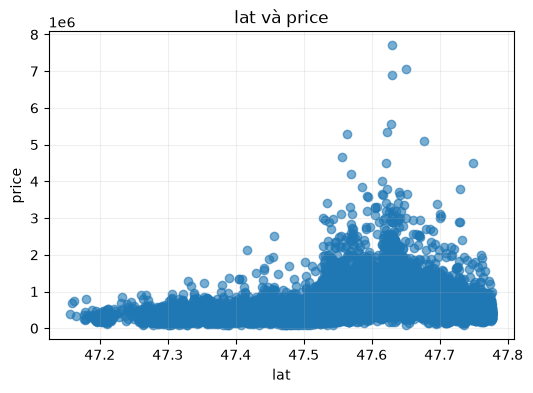

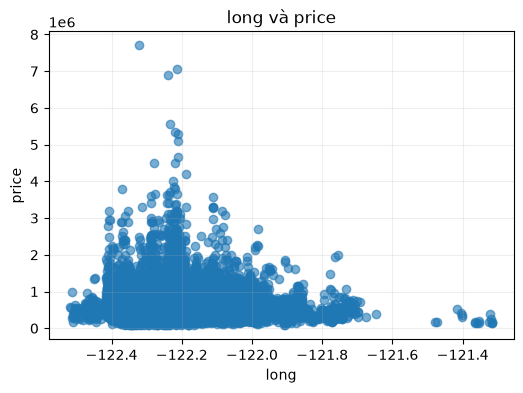

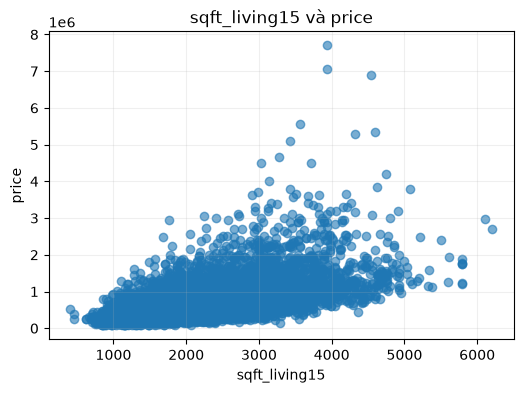

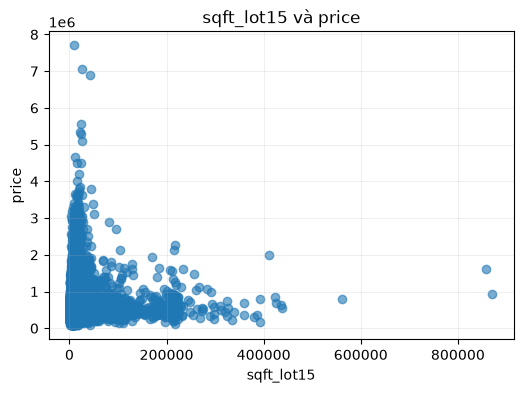

In [ ]:
feature_cols = [col for col in df.columns if col not in ['id', 'date', 'price']]

for col in feature_cols:
    plt.figure(figsize=(6, 4))
    plt.scatter(df[col], df["price"], alpha=0.6)
    plt.xlabel(col)
    plt.ylabel("price")
    plt.title(f"{col} và price")
    plt.grid(alpha=0.2)
    plt.show()

# *PHẦN 3. XÂY DỰNG MÔ HÌNH BASELINE

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

X = df.drop(columns=["id", "date", "price"])
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

baseline_model = LinearRegression()

baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_mse = mean_squared_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = r2_score(y_test, baseline_pred)

print(f"Baseline MAE  = {baseline_mae:.4f}")
print(f"Baseline MSE  = {baseline_mse:.4f}")
print(f"Baseline RMSE = {baseline_rmse:.4f}")
print(f"Baseline R²   = {baseline_r2:.4f}")

Baseline MAE  = 127493.3421
Baseline MSE  = 45173046132.7919
Baseline RMSE = 212539.5166
Baseline R²   = 0.7012


# Bước 9. Phân tích hệ số mô hình baseline

In [30]:
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": baseline_model.coef_
}).sort_values("Coefficient", key=np.abs, ascending=False)

print("Intercept:", baseline_model.intercept_)
coef_df

Intercept: 6643873.52790058


,Feature,Coefficient
14,lat,595968.122144
5,waterfront,562413.070005
15,long,-194585.724048
8,grade,94567.891697
6,view,53641.107022
1,bathrooms,44564.528881
0,bedrooms,-34335.418739
7,condition,24526.710105
4,floors,7003.129520
11,yr_built,-2680.768897


# *PHẦN 4. FEATURE ENGINEERING

# Bước 10. Tạo các feature phi tuyến đơn giản

In [31]:
df_fe = df.copy()

df_fe["sqft_living_squared"] = df_fe["sqft_living"] ** 2
df_fe["sqft_lot_squared"] = df_fe["sqft_lot"] ** 2

df_fe[["sqft_living", "sqft_living_squared", "sqft_lot", "sqft_lot_squared"]].head()

,sqft_living,sqft_living_squared,sqft_lot,sqft_lot_squared
0,1180,1392400,5650,31922500
1,2570,6604900,7242,52446564
2,770,592900,10000,100000000
3,1960,3841600,5000,25000000
4,1680,2822400,8080,65286400


# Bước 11. Tạo feature tương tác

In [32]:
df_fe["bedrooms_bathrooms"] = df_fe["bedrooms"] * df_fe["bathrooms"]

df_fe[["bedrooms", "bathrooms", "bedrooms_bathrooms"]].head()

,bedrooms,bathrooms,bedrooms_bathrooms
0,3,1.00,3.00
1,3,2.25,6.75
2,2,1.00,2.00
3,4,3.00,12.00
4,3,2.00,6.00


# Bước 12. Tạo feature tổng hợp từ nhóm serum

In [33]:
sqft_cols = ["sqft_living", "sqft_lot", "sqft_above", "sqft_basement", "sqft_living15", "sqft_lot15"]

df_fe["sqft_mean"] = df_fe[sqft_cols].mean(axis=1)
df_fe["sqft_std"] = df_fe[sqft_cols].std(axis=1)

df_fe[sqft_cols + ["sqft_mean", "sqft_std"]].head()

,sqft_living,sqft_lot,sqft_above,sqft_basement,sqft_living15,sqft_lot15,sqft_mean,sqft_std
0,1180,5650,1180,0,1340,5650,2500.000000,2486.982107
1,2570,7242,2170,400,1690,7639,3618.500000,3051.869312
2,770,10000,770,0,2720,8062,3720.333333,4255.226512
3,1960,5000,1050,910,1360,5000,2546.666667,1934.359498
4,1680,8080,1680,0,1800,7503,3457.166667,3427.949849


# Bước 13. So sánh tương quan của các feature mới với target

In [34]:
new_features = [
    "sqft_living_squared",
    "sqft_lot_squared",
    "bedrooms_bathrooms",
    "sqft_mean",
    "sqft_std"
]

new_corr = df_fe[new_features + ["price"]].corr()["price"].drop("price")
new_corr.sort_values(key=np.abs, ascending=False).to_frame("corr_with_price")

,corr_with_price
sqft_living_squared,0.727439
bedrooms_bathrooms,0.516641
sqft_mean,0.118811
sqft_std,0.079267
sqft_lot_squared,0.034646


# Bước 14. Huấn luyện mô hình sau Feature Engineering

In [35]:
X_fe = df_fe.drop(columns=["id", "date", "price"])
y_fe = df_fe["price"]

X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe,
    y_fe,
    test_size=0.2,
    random_state=42
)

fe_model = LinearRegression()
fe_model.fit(X_train_fe, y_train_fe)

fe_pred = fe_model.predict(X_test_fe)

fe_mae = mean_absolute_error(y_test_fe, fe_pred)
fe_mse = mean_squared_error(y_test_fe, fe_pred)
fe_rmse = np.sqrt(fe_mse)
fe_r2 = r2_score(y_test_fe, fe_pred)

print(f"Feature Engineering MAE  = {fe_mae:.4f}")
print(f"Feature Engineering MSE  = {fe_mse:.4f}")
print(f"Feature Engineering RMSE = {fe_rmse:.4f}")
print(f"Feature Engineering R²   = {fe_r2:.4f}")

Feature Engineering MAE  = 171064.0497
Feature Engineering MSE  = 81697236682.1694
Feature Engineering RMSE = 285827.2847
Feature Engineering R²   = 0.4596


# Bước 15. So sánh Baseline và Feature Engineering

In [36]:
comparison = pd.DataFrame({
    "Model": ["Baseline", "Feature Engineering"],
    "MAE": [baseline_mae, fe_mae],
    "RMSE": [baseline_rmse, fe_rmse],
    "R2": [baseline_r2, fe_r2]
})

comparison

,Model,MAE,RMSE,R2
0,Baseline,127493.342087,212539.516638,0.701190
1,Feature Engineering,171064.049726,285827.284706,0.459591


# *PHẦN 5. FEATURE SELECTION

# Bước 16. Chọn feature dựa trên mức độ tương quan với target

In [37]:
abs_corr = df.corr(numeric_only=True)["price"].drop("price").abs()
top_features = abs_corr.sort_values(ascending=False).head(5).index.tolist()

print("5 feature có |correlation| cao nhất với price:")
print(top_features)

5 feature có |correlation| cao nhất với price:
['sqft_living', 'grade', 'sqft_above', 'sqft_living15', 'bathrooms']


# Bước 17. Huấn luyện mô hình sau Feature Selection

In [38]:
X_selected = df[top_features]
y_selected = df["price"]

X_train_sel, X_test_sel, y_train_sel, y_test_sel = train_test_split(
    X_selected,
    y_selected,
    test_size=0.2,
    random_state=42
)

selected_model = LinearRegression()
selected_model.fit(X_train_sel, y_train_sel)

selected_pred = selected_model.predict(X_test_sel)

selected_mae = mean_absolute_error(y_test_sel, selected_pred)
selected_rmse = np.sqrt(mean_squared_error(y_test_sel, selected_pred))
selected_r2 = r2_score(y_test_sel, selected_pred)

print(f"Selected Features MAE  = {selected_mae:.4f}")
print(f"Selected Features RMSE = {selected_rmse:.4f}")
print(f"Selected Features R²   = {selected_r2:.4f}")

Selected Features MAE  = 164502.8424
Selected Features RMSE = 261392.1922
Selected Features R²   = 0.5480


# Bước 18. So sánh Baseline

In [39]:
comparison_sel = pd.DataFrame({
    "Model": ["Baseline", "Feature Selection"],
    "MAE": [baseline_mae, selected_mae],
    "RMSE": [baseline_rmse, selected_rmse],
    "R2": [baseline_r2, selected_r2]
})

comparison_sel

,Model,MAE,RMSE,R2
0,Baseline,127493.342087,212539.516638,0.70119
1,Feature Selection,164502.842406,261392.192191,0.54804


# PHẦN 6. ĐÁNH GIÁ VÀ CHẨN ĐOÁN MÔ HÌNH

# Bước 19. So sánh giá trị thực tế và dự đoán

,Actual,Predicted,Residual
0,365000.0,4.612099e+05,-96209.946959
1,865000.0,7.524435e+05,112556.489930
2,1038000.0,1.238490e+06,-200489.802058
3,1490000.0,1.662424e+06,-172423.823320
4,711000.0,7.348896e+05,-23889.595770
5,211000.0,2.825582e+05,-71558.154755
6,790000.0,8.319284e+05,-41928.421789
7,680000.0,5.003700e+05,179630.019127
8,384500.0,3.843639e+05,136.141144
9,605000.0,4.794183e+05,125581.681525


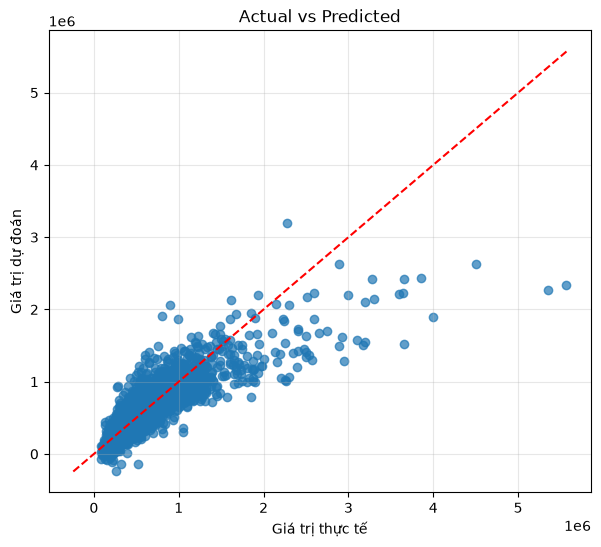

In [41]:
result_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": baseline_pred,
    "Residual": y_test.values - baseline_pred
})

display(result_df.head(10))

plt.figure(figsize=(7, 6))
plt.scatter(y_test, baseline_pred, alpha=0.7)

min_value = min(y_test.min(), baseline_pred.min())
max_value = max(y_test.max(), baseline_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--"
)

plt.xlabel("Giá trị thực tế")
plt.ylabel("Giá trị dự đoán")
plt.title("Actual vs Predicted")
plt.grid(alpha=0.3)
plt.show()

Nhận xét:
* Phân khúc nhà giá thấp và trung bình (< 1.5 triệu - 2 triệu): Các điểm xanh bám khá sát xung quanh đường chéo đứt nét màu đỏ. Điều này chứng tỏ mô hình dự đoán tương đối chính xác đối với những căn nhà ở mức giá phổ thông.

* Phân khúc nhà đắt tiền (> 2 triệu): Các điểm dữ liệu bị tẽ rộng ra giống hình cái phễu (hiện tượng phương sai sai số không đổi) và hầu như đều nằm dưới đường màu đỏ. Điều này có nghĩa là mô hình đang dự đoán thấp hơn rất nhiều so với giá trị thực tế của các căn nhà đắt tiền. Mô hình tuyến tính cơ bản đang gặp khó khăn trong việc nắm bắt các đặc điểm đột biến của bất động sản hạng sang.

* Xuất hiện dự đoán âm: Có một vài điểm nằm dưới vạch 0 của trục Y (Giá trị dự đoán < 0). Đây là một hạn chế kinh điển của thuật toán Linear Regression: mô hình bản chất là một đường thẳng kéo dài vô cực nên nó có thể cho ra kết quả âm (dù thực tế giá nhà không thể nhỏ hơn 0).

# Bước 20. Residual Analysis


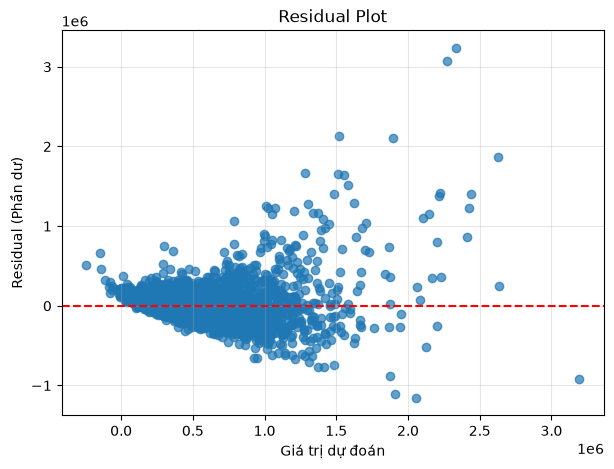

In [42]:
residuals = y_test.values - baseline_pred

plt.figure(figsize=(7, 5))
plt.scatter(baseline_pred, residuals, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Giá trị dự đoán")
plt.ylabel("Residual (Phần dư)")
plt.title("Residual Plot")
plt.grid(alpha=0.3)
plt.show()

Nhận xét:
* Hiện tượng hình phễu (Phương sai sai số thay đổi - Heteroscedasticity): có thể thấy các điểm phân tán không trải đều một cách ngẫu nhiên quanh đường màu đỏ (vạch 0) mà tẽ rộng dần ra thành hình cái phễu khi giá trị dự đoán tăng lên. Điều này vi phạm một giả định quan trọng của hồi quy tuyến tính là sai số phải đồng nhất.  
* Định giá quá thấp nhà đắt tiền: Ở nửa bên phải của biểu đồ (nhóm nhà được dự đoán giá cao), phần lớn các điểm đều nằm tít trên cao với phần dư dương rất lớn (có điểm phần dư lên tới hơn 3 triệu). Vì Phần dư = Thực tế - Dự đoán, phần dư dương lớn có nghĩa là giá thực tế cao hơn rất nhiều so với những gì mô hình dự đoán.   
* Xuất hiện giá dự đoán âm: Ở góc dưới cùng bên trái, có những điểm dữ liệu nằm ở vùng trục X nhỏ hơn 0. Điều này xác nhận lại việc mô hình đang dự đoán giá một số căn nhà bị âm (vô lý trên thực tế).   
* Hoạt động tốt ở phân khúc phổ thông: Ngược lại, ở cụm bên trái (giá trị dự đoán dưới 1 triệu), các điểm dữ liệu bám khá sát và đặc lại quanh đường 0, cho thấy sai số ở phân khúc nhà giá thấp là khá nhỏ và ổn định.   

# Bước 21. Phân phối residual

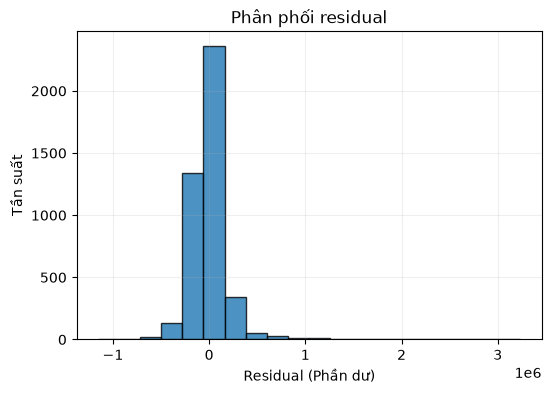

Mean residual: 3145.212396289887


In [44]:
plt.figure(figsize=(6, 4))
plt.hist(residuals, bins=20, edgecolor="black", alpha=0.8)
plt.xlabel("Residual (Phần dư)")
plt.ylabel("Tần suất")
plt.title("Phân phối residual")
plt.grid(alpha=0.2)
plt.show()

print("Mean residual:", np.mean(residuals))

Nhận xét:
* Đa số dự đoán khá tốt: Cột có tần suất (chiều cao) lớn nhất tập trung ngay tại vùng lân cận số 0. Điều này là một tín hiệu tích cực, cho thấy đối với đại đa số các căn nhà trong tập dữ liệu (thường là nhà phổ thông), mô hình có sai số khá nhỏ và dự đoán tương đối sát thực tế.   
* Phân phối bị lệch phải (Right-skewed): Theo lý thuyết hồi quy tuyến tính, phần dư lý tưởng phải có phân phối chuẩn (đối xứng hai bên như hình quả chuông). Tuy nhiên, biểu đồ của bạn lại không đối xứng mà có một chiếc "đuôi" kéo rất dài về phía bên phải, lác đác các điểm kéo dài đến tận mốc 2 triệu - 3 triệu.   
* Khẳng định lại điểm yếu với nhà đắt tiền: Chiếc đuôi dài bên phải này chính là các giá trị phần dư dương khổng lồ (Phần dư = Giá thực tế - Giá dự đoán). Nó minh chứng rõ nét cho việc: có những căn biệt thự, nhà hạng sang giá trị thực rất cao nhưng mô hình lại dự đoán quá thấp (thấp hơn thực tế đến vài triệu đô la). 